# LOOK AT THE ALPHA PARAMETER AS THE SLOPE OF U VS A

we basically found that:  
- differences in alpha arise from large value of A and very small values of U -> blocking regime  
- the distribution of A and U have a smaller std_dev with arctic amplification and they get more peaked.
- a shift of the jet means smaller standard deviation of the winds, especially at higher latitudes. This is not the case for lwa std_dev, which increases where lwa increases. This different shift of the variability of winds and lwa translated in a smaller alpha. This is especially due to events of very low zonal winds and very high LWA.

This looks like a feedback loop -> greater blocking frequency leads to smaller values of ALPHA. Zonal winds become weaker, blocking onset happens for smaller A values, alpha decreases due to the blocking events. The change in alpha doesn't actually impact blocking onset as it is a consequence. If we exclude grid points where the A flux is larger than the carrying capacity, the covariance between U and A should not change. This is far too complicated and noisy to do though.

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np 
import cftime

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
ds_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')
ds_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')

/tmp/ipykernel_148504/3166318099.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped1 = df1.groupby('A_bin')
/tmp/ipykernel_148504/3166318099.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped2 = df2.groupby('A_bin_bis')


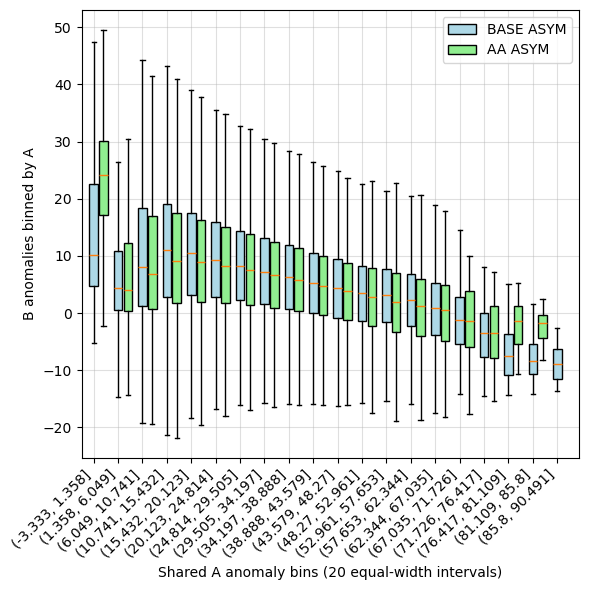

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

lwa = ds_base['dw_lwa'].loc[:,40:80,:]
ucomp = ds_base['ucomp'].loc[:,40:80,:]
p90 = lwa.quantile(1, dim=("time", "lat", "lon"), skipna=True)
mask = lwa.values > p90.values
masked_lwa_base = np.ma.masked_array(lwa.values, mask=mask)
masked_ucomp_base = np.ma.masked_array(ucomp.values, mask=mask)

# First dataset
A = masked_lwa_base.flatten()[:100000000]
B = masked_ucomp_base.flatten()[:100000000]

lwa = ds_aa['dw_lwa'].loc[:,40:80,:]
ucomp = ds_aa['ucomp'].loc[:,40:80,:]
p90 = lwa.quantile(1, dim=("time", "lat", "lon"), skipna=True)
mask = lwa.values > p90.values
masked_lwa_aa = np.ma.masked_array(lwa.values, mask=mask)
masked_ucomp_aa = np.ma.masked_array(ucomp.values, mask=mask)

# Second dataset
A_bis = masked_lwa_aa.flatten()[:100000000]
B_bis = masked_ucomp_aa.flatten()[:100000000]

# Compute SHARED bins from both datasets
global_min = min(A.min(), A_bis.min())
global_max = max(A.max(), A_bis.max())
bins = np.linspace(global_min, global_max, 21)  # 20 equal-width bins => 21 edges

# One figure, one axis
fig, ax = plt.subplots(figsize=(6,6))

# --- First dataset boxplot ---
df1 = pd.DataFrame({'A': A, 'B': B})
df1['A_bin'] = pd.cut(df1['A'], bins=bins)
grouped1 = df1.groupby('A_bin')

data1 = [group['B'].values for _, group in grouped1]

bp1 = ax.boxplot(
    data1,
    positions=range(len(data1)),
    widths=0.35,
    showfliers=False,
    patch_artist=True
)

for box in bp1['boxes']:
    box.set_facecolor('lightblue')

# --- Second dataset boxplot (shift right) ---
df2 = pd.DataFrame({'A_bis': A_bis, 'B_bis': B_bis})
df2['A_bin_bis'] = pd.cut(df2['A_bis'], bins=bins)  # uses SAME bins
grouped2 = df2.groupby('A_bin_bis')

data2 = [group['B_bis'].values for _, group in grouped2]

bp2 = ax.boxplot(
    data2,
    positions=[x + 0.4 for x in range(len(data2))],
    widths=0.35,
    showfliers=False,
    patch_artist=True
)

for box in bp2['boxes']:
    box.set_facecolor('lightgreen')

# --- Labels & legend ---
ax.set_xticks(range(len(data1)))
ax.set_xticklabels([str(interval) for interval in grouped1.groups.keys()],
                   rotation=45, ha='right')

ax.set_ylabel("B anomalies binned by A")
ax.set_xlabel("Shared A anomaly bins (20 equal-width intervals)")
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["BASE ASYM", "AA ASYM"])
ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

# HOW DOES UCOMP AND A DISTRIBUTIONS CHANGE?

In [4]:
ds_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')
ds_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')

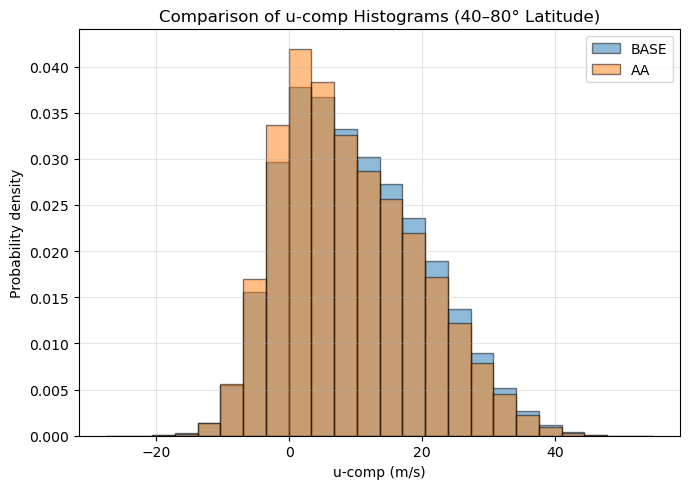

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data
u_base = ds_base['ucomp'].loc[:,40:80,:].values.flatten()[:100000000]
u_aa   = ds_aa['ucomp'].loc[:,40:80,:].values.flatten()[:100000000]

# Choose shared bins
bins = np.linspace(
    min(u_base.min(), u_aa.min()),
    max(u_base.max(), u_aa.max()),
    25  # or 20, but 25 often looks smoother
)

plt.figure(figsize=(7,5))

plt.hist(
    u_base, bins=bins, density=True, alpha=0.5,
    label='BASE', edgecolor='black'
)

plt.hist(
    u_aa, bins=bins, density=True, alpha=0.5,
    label='AA', edgecolor='black'
)

plt.xlabel("u-comp (m/s)")
plt.ylabel("Probability density")
plt.title("Comparison of u-comp Histograms (40–80° Latitude)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


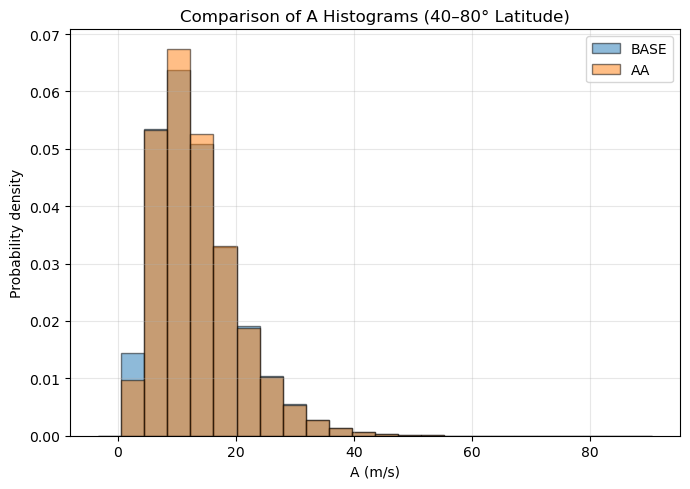

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data
u_base = ds_base['dw_lwa'].loc[:,40:80,:].values.flatten()[:100000000]
u_aa   = ds_aa['dw_lwa'].loc[:,40:80,:].values.flatten()[:100000000]

# Choose shared bins
bins = np.linspace(
    min(u_base.min(), u_aa.min()),
    max(u_base.max(), u_aa.max()),
    25  # or 20, but 25 often looks smoother
)

plt.figure(figsize=(7,5))

plt.hist(
    u_base, bins=bins, density=True, alpha=0.5,
    label='BASE', edgecolor='black'
)

plt.hist(
    u_aa, bins=bins, density=True, alpha=0.5,
    label='AA', edgecolor='black'
)

plt.xlabel("A (m/s)")
plt.ylabel("Probability density")
plt.title("Comparison of A Histograms (40–80° Latitude)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# COMPARE ALPHA DIFFERENCES WITH SOME FIELDS

In [7]:
alpha_aa_std = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51.nc')['alpha_std']
alpha_base_std = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51.nc')['alpha_std']

In [8]:
alpha_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51_masked.nc')['alpha']
alpha_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51_masked.nc')['alpha']

In [9]:
egr_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/egr850_monthly_2.5x2.5_2-51.nc')['eady_growth_rate'].mean('time')
egr_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/egr850_monthly_2.5x2.5_2-51.nc')['eady_growth_rate'].mean('time')

In [10]:
ucomp_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')['ucomp']
ucomp_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')['ucomp']

In [11]:
ucomp_aa_std = ucomp_aa.std(dim='time')
ucomp_base_std = ucomp_base.std(dim='time')

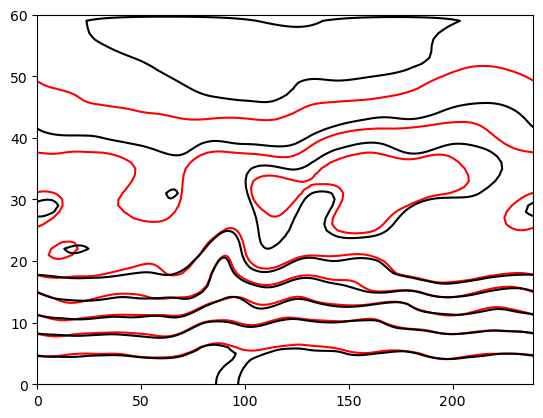

In [12]:
levels = np.arange(2,10,1)
plt.contour(ucomp_aa_std,levels,colors='red')
plt.contour(ucomp_base_std,levels,colors='black')

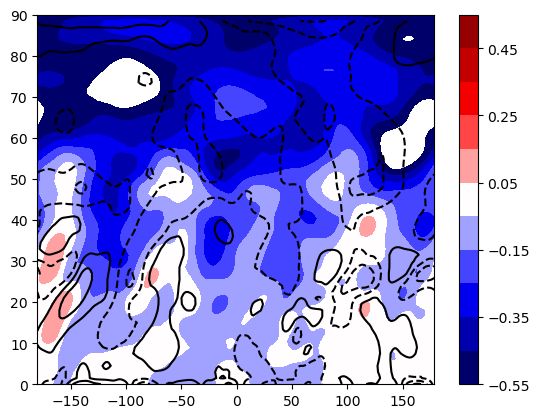

In [13]:
levels = np.arange(-0.55,0.60,0.1)
winds = plt.contourf(ucomp_aa['lon'],ucomp_aa['lat'],ucomp_aa_std-ucomp_base_std,levels,cmap='seismic')
levels_alpha = np.arange(-0.11,0.12,0.02)
plt.contour(alpha_aa['lon'],alpha_aa['lat'],alpha_aa-alpha_base,levels_alpha,colors = 'k')
plt.colorbar(winds)

In [14]:
lwa_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')['dw_lwa']
lwa_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')['dw_lwa']

In [15]:
lwa_aa_std = lwa_aa.std(dim='time')
lwa_base_std = lwa_base.std(dim='time')

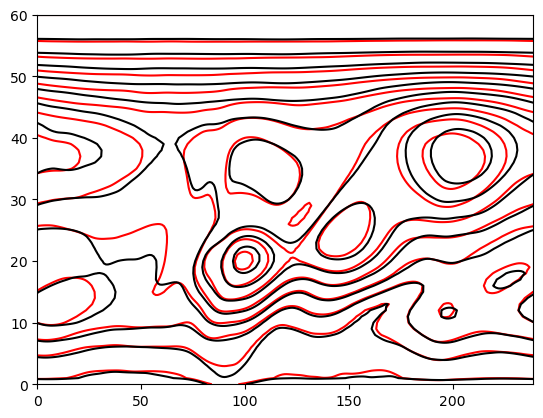

In [16]:
levels = np.arange(0,25,1)
plt.contour(lwa_aa_std,levels,colors='red')
plt.contour(lwa_base_std,levels,colors='black')

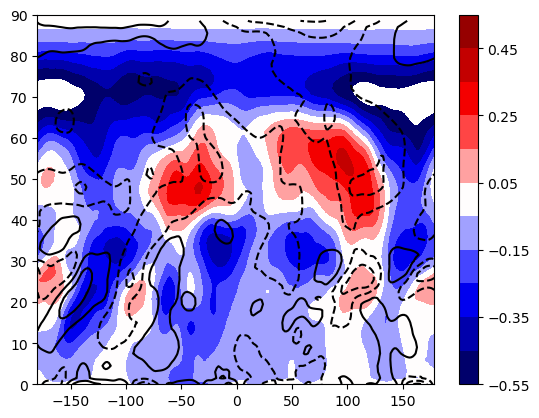

In [17]:
levels = np.arange(-0.55,0.60,0.1)
lwa = plt.contourf(lwa_aa['lon'],lwa_aa['lat'],lwa_aa_std-lwa_base_std,levels,cmap='seismic')
levels_alpha = np.arange(-0.11,0.12,0.02)
plt.contour(alpha_aa['lon'],alpha_aa['lat'],alpha_aa-alpha_base,levels_alpha,colors = 'k')
plt.colorbar(lwa)

In [18]:
plt.contourf(ds['lon'],ds['lat'],ds['dw_lwa'][:1000].mean('time')-ds_base['dw_lwa'][:1000].mean('time'),levels = np.arange(-11,12,2),cmap='coolwarm')
plt.contour(ds['lon'],ds['lat'],alpha_aa-alpha_base,colors = 'k')
plt.colorbar(label='U anomaly [m/s]')

NameError: name 'ds' is not defined

In [ ]:
egr_aa = egr_aa[:,:-1,:]

In [ ]:
levels = np.arange(-0.11,0.12,0.02)
plt.contourf(egr_aa['lon'],egr_aa['lat'],egr_aa[0,:,:]-egr_base[0,:,:],levels,extend='both',cmap='coolwarm')
plt.colorbar(label='U anomaly [m/s]')
plt.contour(ds['lon'],ds['lat'],alpha_aa-alpha_base,colors = 'k')

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [19]:
alpha_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51_masked.nc')['alpha']
alpha_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51_masked.nc')['alpha']

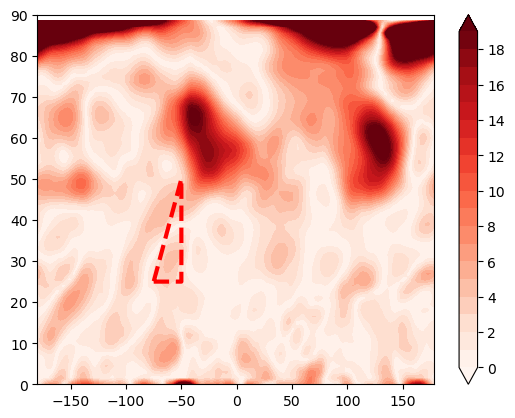

In [20]:
#levels = np.arange(-0.055,0.06,0.01)
levels = np.arange(0,20,1)
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)
plt.contourf(alpha_aa['lon'],alpha_aa['lat'],abs(alpha_aa-alpha_base)*100/abs(alpha_aa),levels,extend='both',cmap='Reds')
plt.plot(lons, lats, linestyle='--', linewidth=3, color='red')
plt.colorbar()

In [21]:
alpha_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51_masked.nc')['alpha']
alpha_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51_masked.nc')['alpha']
block_freq_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')['LWAA_freq']
block_freq_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')['LWAA_freq']

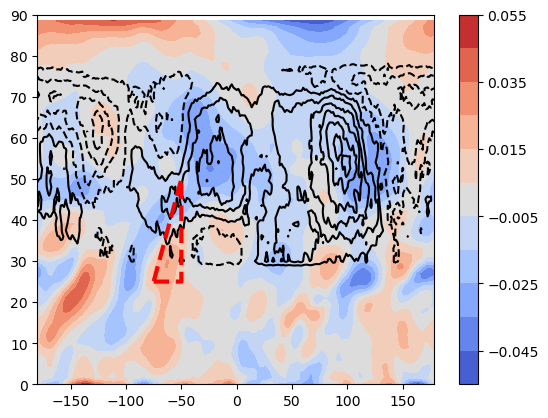

In [22]:
levels = np.arange(-0.055,0.06,0.01)
levels_block = np.arange(-1.1,1.2,0.2)
alpha_diff = plt.contourf(alpha_aa['lon'],alpha_aa['lat'],alpha_aa-alpha_base,levels,cmap='coolwarm')
plt.contour(alpha_aa['lon'],alpha_aa['lat'],(block_freq_aa-block_freq_base),levels_block,colors='k')
plt.plot(lons, lats, linestyle='--', linewidth=3, color='red')
plt.colorbar(alpha_diff)

In [ ]:
plt.plot((alpha_aa-alpha_base).mean('lon'))